# Laboratorio 01: Exploración del dataset de madurez del mango

**Investigación:** Clasificación del estado de madurez del mango mediante aprendizaje profundo.

**Artículo base:** Ahmad et al. (2026) - SE-DBIRNet.

**Dataset:** Mango Shelf-Life Dataset (4,428 imágenes).

## Objetivo
Explorar y analizar la distribución de imágenes y las
categorías de madurez antes de entrenar el modelo.

## Etapas de trabajo
1. Cargar el dataset.
2. Identificar las clases de maduración.
3. Analizar la distribución de imágenes.
4. Visualizar ejemplos de cada clase.
5. Preparar los datos para el entrenamiento.

In [ ]:
import sys

print("Python:", sys.version)
print("Entorno:", sys.executable)
print("Notebook iniciado correctamente")

## 2. Análisis de la distribución de imágenes

El dataset está organizado en cinco categorías de maduración
del mango: Unripe, Semripe, FullyRipe, Overripe y Perished.

Se realizará un conteo de las imágenes correspondientes
a cada categoría para identificar posibles desequilibrios
entre las clases.

In [ ]:
from pathlib import Path

# Corregir la ruta del dataset
ruta_dataset = Path("../data/entrenamiento/Mango Shelf-Life Dataset")

# Nombres reales de las carpetas
clases = [
    "Unripe",
    "Semiripe",
    "Fully Ripe",
    "Overripe",
    "Perished"
]

extensiones = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

total_imagenes = 0

print("DISTRIBUCIÓN DEL DATASET")
print("-" * 40)

for clase in clases:
    carpeta = ruta_dataset / clase

    imagenes = [
        archivo for archivo in carpeta.rglob("*")
        if archivo.is_file()
        and archivo.suffix.lower() in extensiones
    ]

    cantidad = len(imagenes)
    total_imagenes += cantidad

    print(f"{clase:15}: {cantidad} imágenes")

print("-" * 40)
print(f"TOTAL: {total_imagenes} imágenes")

## 3. Visualización de los estados de maduración

Se visualizará una imagen representativa de cada una de las
cinco categorías presentes en el Mango Shelf-Life Dataset.

El propósito es identificar diferencias visuales relacionadas
con el color, la textura y las características externas del
fruto, que posteriormente serán analizadas mediante
aprendizaje profundo.

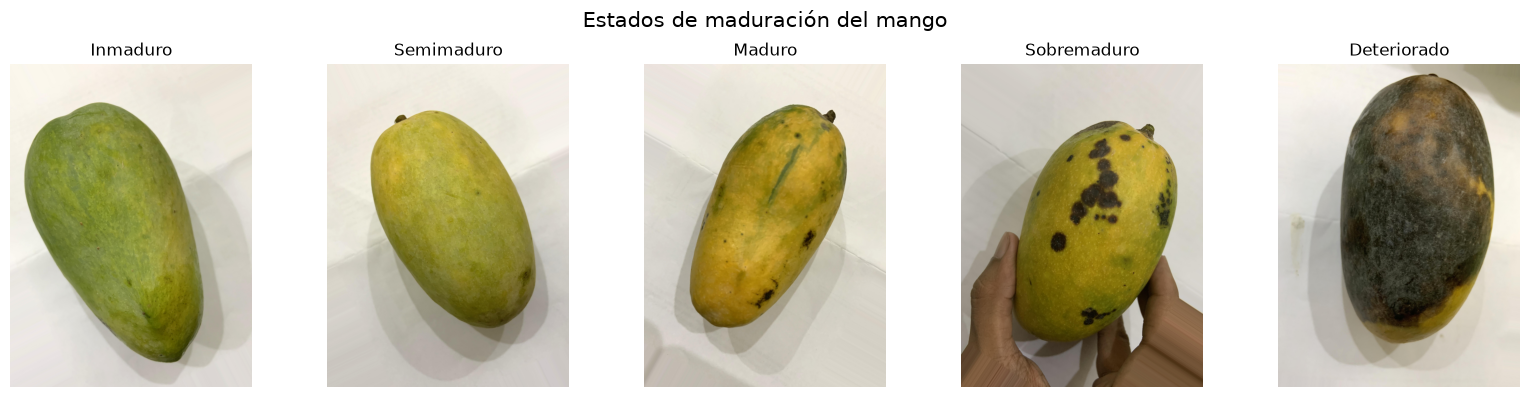

In [1]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Ruta del dataset
ruta_dataset = Path("../data/entrenamiento/Mango Shelf-Life Dataset")

# Clases originales
clases = [
    "Unripe",
    "Semiripe",
    "Fully Ripe",
    "Overripe",
    "Perished"
]

# Traducción de las categorías
nombres = [
    "Inmaduro",
    "Semimaduro",
    "Maduro",
    "Sobremaduro",
    "Deteriorado"
]

extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for i, clase in enumerate(clases):

    carpeta = ruta_dataset / clase

    imagenes = sorted(
        f for f in carpeta.iterdir()
        if f.is_file() and f.suffix.lower() in extensiones
    )

    if not imagenes:
        print(f"No se encontraron imágenes en: {clase}")
        axes[i].axis("off")
        continue

    with Image.open(imagenes[0]) as img:
        imagen = img.convert("RGB")
        axes[i].imshow(imagen)

    axes[i].set_title(nombres[i])
    axes[i].axis("off")

plt.suptitle("Estados de maduración del mango", fontsize=15)
plt.tight_layout()
plt.show()

## 4. Análisis de distribución de clases

Se analizará la cantidad de imágenes correspondientes
a cada estado de maduración del mango.

Este análisis permitirá identificar posibles desequilibrios
entre las categorías que podrían afectar el entrenamiento
y la capacidad de clasificación del modelo SE-DBIRNet.

DISTRIBUCIÓN DE IMÁGENES
---------------------------------------------
Unripe         :  1350 (30.49%)
Semiripe       :  1157 (26.13%)
Fully Ripe     :   841 (18.99%)
Overripe       :   896 (20.23%)
Perished       :   184 (4.16%)
---------------------------------------------
TOTAL: 4428 imágenes


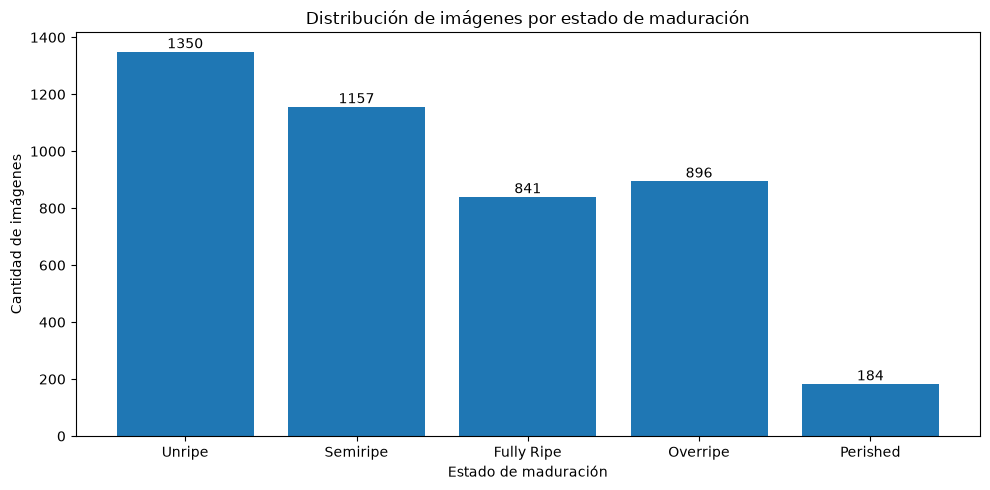

In [2]:
import matplotlib.pyplot as plt
from pathlib import Path

# Dataset original
ruta_dataset = Path("../data/entrenamiento/Mango Shelf-Life Dataset")

clases = [
    "Unripe",
    "Semiripe",
    "Fully Ripe",
    "Overripe",
    "Perished"
]

extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Contar imágenes
cantidades = []

for clase in clases:
    carpeta = ruta_dataset / clase

    imagenes = [
        f for f in carpeta.rglob("*")
        if f.is_file() and f.suffix.lower() in extensiones
    ]

    cantidades.append(len(imagenes))

total = sum(cantidades)

# Resultados
print("DISTRIBUCIÓN DE IMÁGENES")
print("-" * 45)

for clase, cantidad in zip(clases, cantidades):
    porcentaje = (cantidad / total * 100) if total else 0
    print(f"{clase:15}: {cantidad:5} ({porcentaje:.2f}%)")

print("-" * 45)
print(f"TOTAL: {total} imágenes")

# Gráfico de barras
plt.figure(figsize=(10, 5))

barras = plt.bar(clases, cantidades)

for barra, cantidad in zip(barras, cantidades):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        str(cantidad),
        ha="center",
        va="bottom"
    )

plt.title("Distribución de imágenes por estado de maduración")
plt.xlabel("Estado de maduración")
plt.ylabel("Cantidad de imágenes")
plt.tight_layout()
plt.show()

**Observación importante:** el dataset está desbalanceado. La categoría Perished tiene muchas menos imágenes que las demás. Durante el entrenamiento tendremos que considerar estrategias como ponderación de clases para evitar que el modelo favorezca las categorías mayoritarias.

## 5. División del dataset

Se dividirán las imágenes en tres subconjuntos:

- Entrenamiento: 70 %
- Validación: 15 %
- Prueba: 15 %

Se utilizará una división estratificada para mantener
aproximadamente la misma proporción de clases.

Se establecerá una semilla aleatoria de 42 para garantizar
la reproducibilidad del experimento.

In [ ]:
%pip install scikit-learn

In [5]:
from pathlib import Path
from sklearn.model_selection import train_test_split
import csv

ruta_dataset = Path("../data/entrenamiento/Mango Shelf-Life Dataset")

clases = [
    "Unripe",
    "Semiripe",
    "Fully Ripe",
    "Overripe",
    "Perished"
]

extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

registros = []

for clase in clases:
    for archivo in sorted((ruta_dataset / clase).rglob("*")):
        if archivo.is_file() and archivo.suffix.lower() in extensiones:
            registros.append((str(archivo.resolve()), clase))

# Primera división: 70 % entrenamiento, 30 % temporal
train, temporal = train_test_split(
    registros,
    test_size=0.30,
    random_state=42,
    stratify=[r[1] for r in registros]
)

# Segunda división: 15 % validación y 15 % prueba
valid, test = train_test_split(
    temporal,
    test_size=0.50,
    random_state=42,
    stratify=[r[1] for r in temporal]
)

print("RESULTADOS DE LA DIVISIÓN")
print("-" * 40)
print("Entrenamiento:", len(train))
print("Validación:", len(valid))
print("Prueba:", len(test))
print("Total:", len(train) + len(valid) + len(test))

RESULTADOS DE LA DIVISIÓN
----------------------------------------
Entrenamiento: 3099
Validación: 664
Prueba: 665
Total: 4428


## 6. Registro de la división del dataset

Se almacenará la distribución de las imágenes en un archivo
CSV para garantizar la trazabilidad y reproducibilidad
de los experimentos.

Cada registro contendrá:
- Ruta de la imagen.
- Categoría de maduración.
- Conjunto asignado (train, valid o test).

La división se considera preliminar hasta verificar
posibles imágenes duplicadas.

In [6]:
import csv
from pathlib import Path

# Carpeta de resultados
ruta_resultados = Path("../resultados")
ruta_resultados.mkdir(parents=True, exist_ok=True)

# Archivo CSV
archivo_csv = ruta_resultados / "division_dataset_preliminar.csv"

# Guardar registros
with open(archivo_csv, "w", newline="", encoding="utf-8-sig") as archivo:
    writer = csv.writer(archivo)

    writer.writerow(["ruta", "clase", "conjunto"])

    for ruta, clase in train:
        writer.writerow([ruta, clase, "train"])

    for ruta, clase in valid:
        writer.writerow([ruta, clase, "valid"])

    for ruta, clase in test:
        writer.writerow([ruta, clase, "test"])

print("Archivo CSV creado correctamente")
print("Ubicación:", archivo_csv.resolve())

Archivo CSV creado correctamente
Ubicación: D:\ronex_pozo\CLASES\Cursos 2026 - II\Metodologia de la investigacion\Mango_Madurez_ML\resultados\division_dataset_preliminar.csv


In [ ]:
%pip install pandas

In [2]:
import pandas as pd
from pathlib import Path

# Ruta correcta del CSV
ruta_csv = Path("../resultados/division_dataset_preliminar.csv")

# Verificar existencia
print("¿Existe el archivo?:", ruta_csv.exists())

# Leer CSV
df = pd.read_csv(ruta_csv)

print("Total de registros:", len(df))

print("\nDistribución por conjunto y clase:")
print(pd.crosstab(df["clase"], df["conjunto"]))

¿Existe el archivo?: True
Total de registros: 4428

Distribución por conjunto y clase:
conjunto    test  train  valid
clase                         
Fully Ripe   126    588    127
Overripe     135    627    134
Perished      27    129     28
Semiripe     174    810    173
Unripe       203    945    202


## 7. Detección de imágenes duplicadas

Se analizarán las 4,428 imágenes mediante el algoritmo
SHA-256 para identificar archivos con contenido idéntico.

Objetivos:
- Detectar imágenes duplicadas.
- Identificar duplicados entre entrenamiento,
  validación y prueba.
- Prevenir fugas de información (data leakage).
- Garantizar una evaluación más confiable del modelo.

Este procedimiento detecta duplicados exactos, pero no
necesariamente fotografías similares del mismo fruto.

In [3]:
import pandas as pd
import hashlib
from pathlib import Path

# Cargar la división del dataset
df = pd.read_csv(
    "../resultados/division_dataset_preliminar.csv"
)

# Función para calcular el hash de cada imagen
def calcular_hash(ruta):
    sha256 = hashlib.sha256()

    with open(ruta, "rb") as archivo:
        for bloque in iter(
            lambda: archivo.read(1024 * 1024), b""
        ):
            sha256.update(bloque)

    return sha256.hexdigest()

# Calcular hash de todas las imágenes
df["hash"] = df["ruta"].apply(calcular_hash)

# Identificar imágenes duplicadas
duplicados = df[
    df.duplicated(subset="hash", keep=False)
]

# Identificar duplicados entre conjuntos
grupos = df.groupby("hash").agg(
    cantidad=("ruta", "size"),
    conjuntos=("conjunto", "nunique"),
    clases=("clase", "nunique")
)

fugas = grupos[
    (grupos["cantidad"] > 1) &
    (grupos["conjuntos"] > 1)
]

print("ANÁLISIS DE DUPLICADOS")
print("-" * 45)

print("Total de imágenes:", len(df))
print("Imágenes con duplicados:", len(duplicados))
print("Grupos de imágenes duplicadas:",
      duplicados["hash"].nunique())
print("Grupos duplicados entre conjuntos:", len(fugas))
print("Grupos con etiquetas diferentes:",
      len(grupos[
          (grupos["cantidad"] > 1) &
          (grupos["clases"] > 1)
      ]))

if len(fugas) == 0:
    print("\nNo se detectaron duplicados exactos entre conjuntos.")
else:
    print("\nADVERTENCIA: existen duplicados entre conjuntos.")

ANÁLISIS DE DUPLICADOS
---------------------------------------------
Total de imágenes: 4428
Imágenes con duplicados: 0
Grupos de imágenes duplicadas: 0
Grupos duplicados entre conjuntos: 0
Grupos con etiquetas diferentes: 0

No se detectaron duplicados exactos entre conjuntos.


## 8. Detección de imágenes visualmente similares

Se utilizará el algoritmo Perceptual Hash (pHash)
para identificar posibles imágenes similares entre
entrenamiento, validación y prueba.

Se considerarán como candidatas a revisión las parejas
de imágenes con distancia de Hamming menor o igual a 4.

Este análisis complementa la detección SHA-256 y busca
reducir el riesgo de fuga de información.

In [ ]:
%pip install ImageHash

In [6]:
# Obtener los conjuntos una sola vez
conjuntos = df["conjunto"].tolist()

similares = []

# Comparación optimizada
for i in range(len(hashes)):
    for j in range(i + 1, len(hashes)):

        if conjuntos[i] == conjuntos[j]:
            continue

        distancia = (hashes[i] ^ hashes[j]).bit_count()

        if distancia <= 4:
            similares.append((i, j, distancia))

print("ANÁLISIS DE SIMILITUD")
print("-" * 45)
print("Imágenes analizadas:", len(hashes))
print("Parejas similares entre conjuntos:", len(similares))

ANÁLISIS DE SIMILITUD
---------------------------------------------
Imágenes analizadas: 4428
Parejas similares entre conjuntos: 748


In [1]:
import sys
import platform

print("Python:", sys.version.split()[0])
print("Sistema:", platform.system())
print("Entorno:", sys.executable)

Python: 3.12.10
Sistema: Windows
Entorno: D:\ronex_pozo\CLASES\Cursos 2026 - II\Metodologia de la investigacion\Mango_Madurez_ML\.venv\Scripts\python.exe


In [5]:
import subprocess

resultado = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

if resultado.returncode == 0:
    print(resultado.stdout)
else:
    print("No se detectó una GPU NVIDIA mediante nvidia-smi.")
    print("Podremos utilizar PyTorch con CPU.")

FileNotFoundError: [WinError 2] El sistema no puede encontrar el archivo especificado

In [ ]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu

In [4]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA disponible:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dispositivo de entrenamiento:", device)

PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
CUDA disponible: False
Dispositivo de entrenamiento: cpu
